In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

In [2]:
docs = [
    "Machine learning is a subset of artificial intelligence",
    "Artificial intelligence and machine learning are changing the world",
    "The football match was exciting and the crowd cheered loudly",
    "The cricket match ended with a thrilling last over",
    "Deep learning uses neural networks for machine learning tasks",
]
labels = [f"D{i+1}" for i in range(len(docs))]

In [3]:
def cosine_manual(a, b):
    return np.dot(a, b) / (np.linalg.norm(a) * np.linalg.norm(b))

vec = TfidfVectorizer(stop_words="english")
X = vec.fit_transform(docs).toarray()
print("D1 vs D2:", round(cosine_manual(X[0], X[1]), 4))
print("D1 vs D3:", round(cosine_manual(X[0], X[2]), 4))

D1 vs D2: 0.6
D1 vs D3: 0.0


,D1,D2,D3,D4,D5
D1,1.00,0.600,0.000,0.000,0.280
D2,0.60,1.000,0.000,0.000,0.244
D3,0.00,0.000,1.000,0.143,0.000
D4,0.00,0.000,0.143,1.000,0.000
D5,0.28,0.244,0.000,0.000,1.000


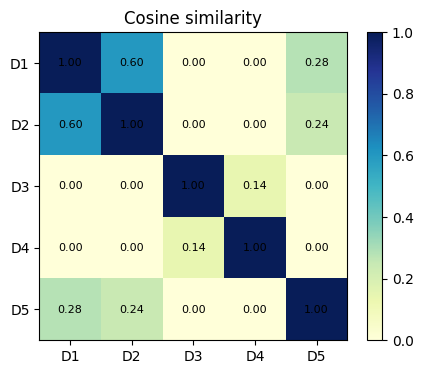

In [4]:
sim = cosine_similarity(X)
df_sim = pd.DataFrame(sim, index=labels, columns=labels).round(3)
display(df_sim)

plt.figure(figsize=(5, 4))
plt.imshow(sim, cmap="YlGnBu", vmin=0, vmax=1)
plt.xticks(range(len(docs)), labels); plt.yticks(range(len(docs)), labels)
for i in range(len(docs)):
    for j in range(len(docs)):
        plt.text(j, i, f"{sim[i,j]:.2f}", ha="center", va="center", fontsize=8)
plt.colorbar(); plt.title("Cosine similarity"); plt.show()

In [5]:
s = sim.copy(); np.fill_diagonal(s, -1)
i, j = np.unravel_index(s.argmax(), s.shape)
print(f"Most similar pair: {labels[i]} & {labels[j]}  (score {s[i,j]:.3f})")
print(" ->", docs[i]); print(" ->", docs[j])

query = ["neural networks and machine learning"]
scores = cosine_similarity(vec.transform(query), X)[0]
for k in scores.argsort()[::-1]:
    print(f"{scores[k]:.3f}  {docs[k]}")

Most similar pair: D1 & D2  (score 0.600)
 -> Machine learning is a subset of artificial intelligence
 -> Artificial intelligence and machine learning are changing the world
0.730  Deep learning uses neural networks for machine learning tasks
0.295  Machine learning is a subset of artificial intelligence
0.257  Artificial intelligence and machine learning are changing the world
0.000  The football match was exciting and the crowd cheered loudly
0.000  The cricket match ended with a thrilling last over
